<a href="https://colab.research.google.com/github/Oumaima257/analyse-emplois-data/blob/main/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import os
print(os.listdir())

['.config', 'Telco-Customer-Churn.csv', 'sample_data']


In [7]:
import pandas as pd

df = pd.read_csv("Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()
print("Doublons :", df.duplicated().sum())
df["Churn"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,count
Churn,
No,5174
Yes,1869


In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Valeurs manquantes :")
print(df.isnull().sum()[df.isnull().sum() > 0])

Valeurs manquantes :
TotalCharges    11
dtype: int64


In [10]:
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)

# Churn en 0/1 : indispensable pour le modèle plus tard
df["Churn_num"] = (df["Churn"] == "Yes").astype(int)

print(df.shape)
print(df["Churn_num"].mean().round(3))

(7032, 22)
0.266


In [11]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn


In [12]:
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)

# Churn en 0/1 : indispensable pour le modèle plus tard
df["Churn_num"] = (df["Churn"] == "Yes").astype(int)

print(df.shape)
print(df["Churn_num"].mean().round(3))

(7032, 22)
0.266


La colonne TotalCharges contenait 11 cases vides, toutes pour des clients avec une ancienneté de 0 mois (pas encore facturés). Je les ai retirées : 11 lignes sur 7 043, cela n’affecte pas l’analyse

In [13]:
taux_global = df["Churn_num"].mean()
print(f"Taux de départ global : {taux_global:.1%}")

Taux de départ global : 26.6%


In [14]:
par_contrat = (df.groupby("Contract")["Churn_num"]
                 .agg(["mean", "count"])
                 .rename(columns={"mean": "taux_depart", "count": "nb_clients"}))
par_contrat["taux_depart"] = (par_contrat["taux_depart"] * 100).round(1)
par_contrat

,taux_depart,nb_clients
Contract,,
Month-to-month,42.7,3875
One year,11.3,1472
Two year,2.8,1685


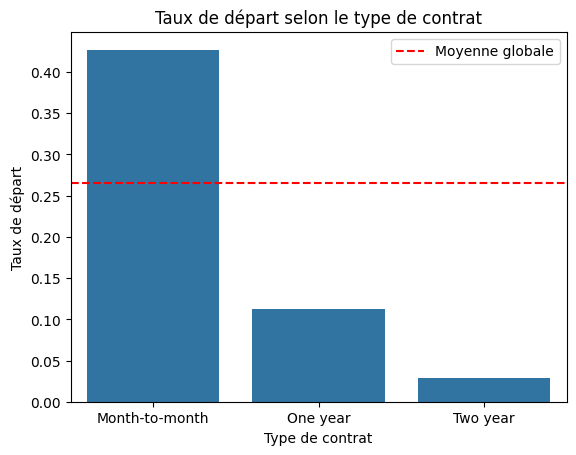

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(data=df, x="Contract", y="Churn_num",
            order=["Month-to-month", "One year", "Two year"], errorbar=None)
plt.axhline(taux_global, color="red", linestyle="--", label="Moyenne globale")
plt.title("Taux de départ selon le type de contrat")
plt.xlabel("Type de contrat")
plt.ylabel("Taux de départ")
plt.legend()
plt.show()

In [16]:
df["tranche_anciennete"] = pd.cut(df["tenure"],
                                  bins=[0, 12, 24, 48, 72],
                                  labels=["0-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"])

df.groupby("tranche_anciennete", observed=True)["Churn_num"].mean().mul(100).round(1)

,Churn_num
tranche_anciennete,
0-12 mois,47.7
13-24 mois,28.7
25-48 mois,20.4
49-72 mois,9.5


Le risque de resilier diminue avec l’ancienneté .: 47,7 % pour les clients de moins d’un an, contre 9,5 % après 4 ans La première année est donc la période à surveiller en priorité : une offre de fidélisation ciblée sur les nouveaux clients aurait le plus d’impact

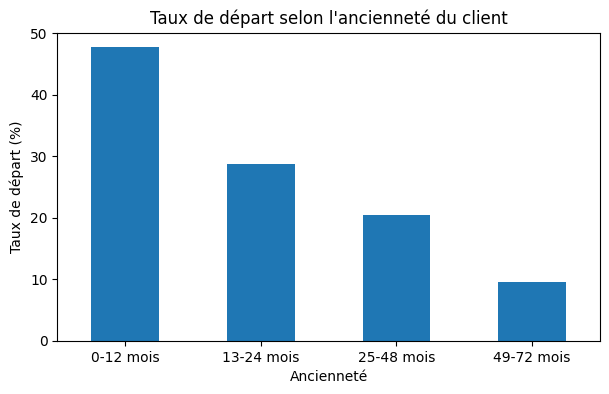

In [17]:
taux_anciennete = df.groupby("tranche_anciennete", observed=True)["Churn_num"].mean() * 100

taux_anciennete.plot(kind="bar", figsize=(7, 4))
plt.title("Taux de départ selon l'ancienneté du client")
plt.xlabel("Ancienneté")
plt.ylabel("Taux de départ (%)")
plt.xticks(rotation=0)
plt.show()

In [18]:
internet = (df.groupby("InternetService")["Churn_num"]
              .agg(["mean", "count"])
              .rename(columns={"mean": "taux_depart", "count": "nb_clients"}))
internet["taux_depart"] = (internet["taux_depart"] * 100).round(1)
internet.sort_values("taux_depart", ascending=False)

,taux_depart,nb_clients
InternetService,,
Fiber optic,41.9,3096
DSL,19.0,2416
No,7.4,1520


In [19]:
paiement = (df.groupby("PaymentMethod")["Churn_num"]
              .agg(["mean", "count"])
              .rename(columns={"mean": "taux_depart", "count": "nb_clients"}))
paiement["taux_depart"] = (paiement["taux_depart"] * 100).round(1)
paiement.sort_values("taux_depart", ascending=False)

,taux_depart,nb_clients
PaymentMethod,,
Electronic check,45.3,2365
Mailed check,19.2,1604
Bank transfer (automatic),16.7,1542
Credit card (automatic),15.3,1521


In [20]:
df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(1)

,mean,median
Churn,,
No,61.3,64.4
Yes,74.4,79.6


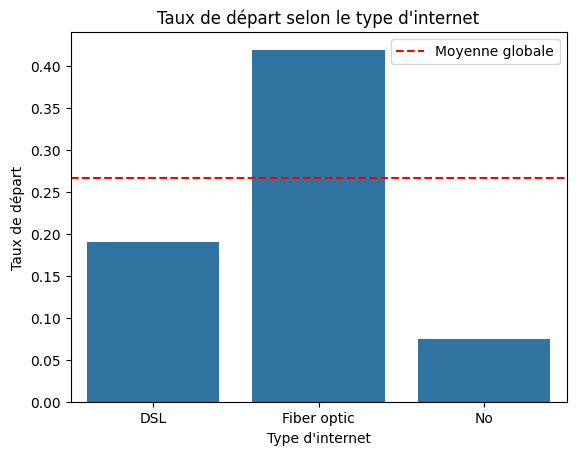

In [21]:
sns.barplot(data=df, x="InternetService", y="Churn_num", errorbar=None)
plt.axhline(df["Churn_num"].mean(), color="red", linestyle="--", label="Moyenne globale")
plt.title("Taux de départ selon le type d'internet")
plt.xlabel("Type d'internet")
plt.ylabel("Taux de départ")
plt.legend()
plt.show()

In [22]:
(df.pivot_table(index="InternetService", columns="Contract",
                values="Churn_num", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,32.2,9.3,1.9
Fiber optic,54.6,19.3,7.2
No,18.9,2.5,0.8


In [23]:
# Variables à prédire (y) et variables explicatives (X)
y = df["Churn_num"]
X = df.drop(columns=["customerID", "Churn", "Churn_num", "tranche_anciennete"])

# Transformer chaque colonne de texte en colonnes 0/1
X = pd.get_dummies(X, drop_first=True, dtype=int)

print(X.shape)
X.head()

(7032, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)
print("Taux de départ (entraînement) :", round(y_train.mean(), 3))
print("Taux de départ (test) :", round(y_test.mean(), 3))

Entraînement : (5625, 30)
Test : (1407, 30)
Taux de départ (entraînement) : 0.266
Taux de départ (test) : 0.266


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

modele_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
modele_lr.fit(X_train, y_train)

pred_lr = modele_lr.predict(X_test)
print(classification_report(y_test, pred_lr, target_names=["Reste", "Part"]))

              precision    recall  f1-score   support

       Reste       0.85      0.89      0.87      1033
        Part       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [27]:
from sklearn.ensemble import RandomForestClassifier

modele_rf = RandomForestClassifier(n_estimators=200, random_state=42)
modele_rf.fit(X_train, y_train)

pred_rf = modele_rf.predict(X_test)
print(classification_report(y_test, pred_rf, target_names=["Reste", "Part"]))

              precision    recall  f1-score   support

       Reste       0.83      0.89      0.86      1033
        Part       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

resultats = pd.DataFrame({
    "Modèle": ["Régression logistique", "Random forest"],
    "Accuracy": [accuracy_score(y_test, p) for p in (pred_lr, pred_rf)],
    "Précision": [precision_score(y_test, p) for p in (pred_lr, pred_rf)],
    "Rappel": [recall_score(y_test, p) for p in (pred_lr, pred_rf)],
    "F1": [f1_score(y_test, p) for p in (pred_lr, pred_rf)],
}).round(3)
resultats

,Modèle,Accuracy,Précision,Rappel,F1
0,Régression logistique,0.804,0.648,0.575,0.609
1,Random forest,0.787,0.621,0.508,0.559


In [31]:
modele_lr_b = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
)
modele_lr_b.fit(X_train, y_train)

pred_lr_b = modele_lr_b.predict(X_test)
print(classification_report(y_test, pred_lr_b, target_names=["Reste", "Part"]))

              precision    recall  f1-score   support

       Reste       0.91      0.70      0.79      1033
        Part       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [32]:
proba = modele_lr.predict_proba(X_test)[:, 1]

lignes = []
for seuil in [0.2, 0.3, 0.4, 0.5]:
    pred = (proba >= seuil).astype(int)
    lignes.append({
        "Seuil": seuil,
        "Précision": precision_score(y_test, pred),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Clients ciblés": pred.sum()
    })

pd.DataFrame(lignes).round(3)

,Seuil,Précision,Rappel,F1,Clients ciblés
0,0.2,0.458,0.869,0.600,710
1,0.3,0.512,0.759,0.611,555
2,0.4,0.578,0.684,0.627,443
3,0.5,0.648,0.575,0.609,332


Le seuil 0.4 donne le meilleur F1-score : 62,7 %.
Il représente le meilleur équilibre entre Precision et Recall parmi les quatre seuils testés.
